# View EMG data

Loads one recorded trial (WAVELETECH 18-channel armband, 2000 Hz) and plots raw and filtered EMG, prompts, RMS envelopes, spectrum and IMU.

Set `SESSION` to a folder under `data/raw/` for real recordings; it defaults to the synthetic example `examples/S01`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from deftemg_acquisition.analysis.filtering import filter_trial  # noqa: E402 (after the sys.path line)
from deftemg_acquisition.data.trials import load_trial, scan_trials  # noqa: E402

FS = 2000.0
SESSION = ROOT / "examples" / "S01"  # e.g. ROOT / "data" / "raw" / "<session>"

## Trials in the session

In [2]:
infos = scan_trials([SESSION])
for i, info in enumerate(infos):
    print(
        i,
        info.id,
        "| label:",
        info.label,
        "| prompts:",
        info.n_prompts,
        "| synthetic:",
        info.synthetic,
    )

0 S01/trial_001_calibration | label: calibration | prompts: 5 | synthetic: True
1 S01/trial_002_syn_single_b01 | label: syn_single_b01 | prompts: 8 | synthetic: True
2 S01/trial_003_syn_multi_b02 | label: syn_multi_b02 | prompts: 8 | synthetic: True


In [3]:
TRIAL = 1  # index from the list above
trial = load_trial(infos[TRIAL].npz_path)
filt = filter_trial(trial, fs_hz=FS)  # 20 Hz high-pass + powerline notches

t = (trial.emg_t_ns - trial.emg_t_ns[0]) / 1e9
n, n_ch = trial.emg_uv.shape
n_seg = len(trial.segment_bounds())
print(f"{trial.id}: {n} samples, {n_ch} channels, {t[-1]:.1f} s, {n_seg} continuous segment(s)")

S01/trial_002_syn_single_b01: 46630 samples, 18 channels, 23.3 s, 1 continuous segment(s)


## All channels (filtered), with prompts shaded

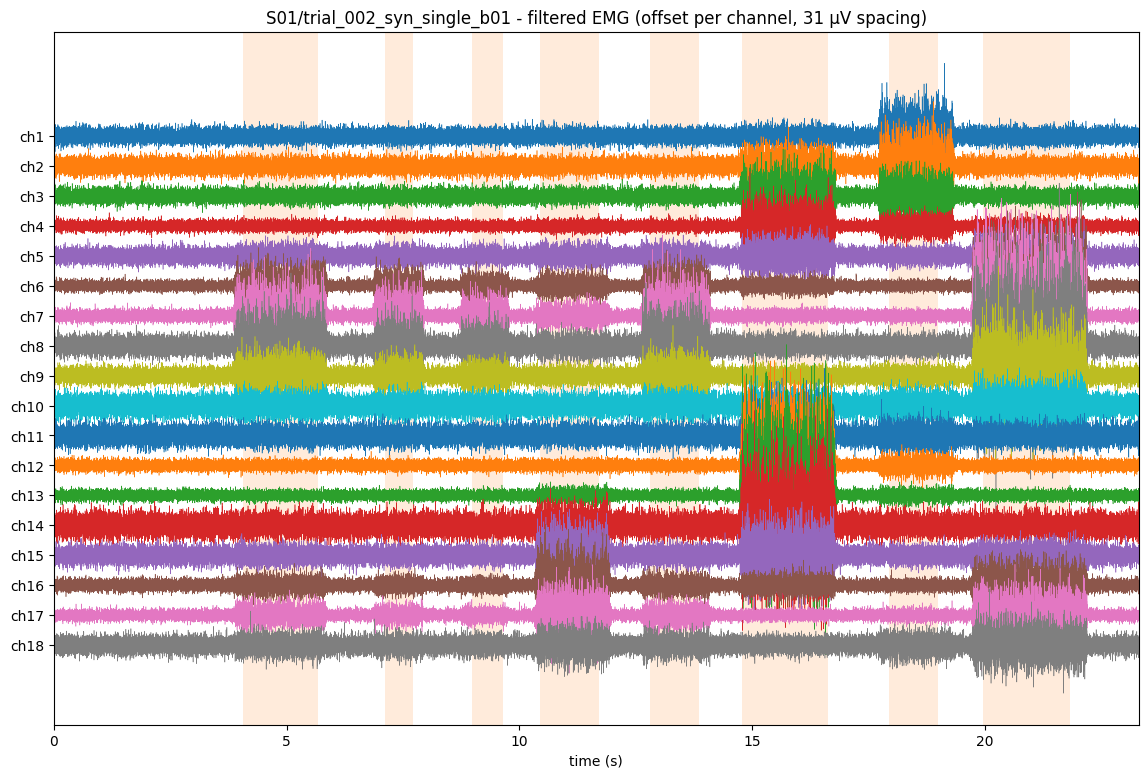

In [4]:
def shade_prompts(ax, trial):
    if trial.prompts is None:
        return
    t0 = trial.emg_t_ns[0]
    for on, off in zip(trial.prompts.onset_ns, trial.prompts.offset_ns, strict=True):
        ax.axvspan((on - t0) / 1e9, (off - t0) / 1e9, color="tab:orange", alpha=0.15, lw=0)


x = filt.emg_uv
spacing = 4 * np.median(np.std(x, axis=0)) or 1.0
fig, ax = plt.subplots(figsize=(14, 9))
for c in range(n_ch):
    ax.plot(t, x[:, c] - c * spacing, lw=0.4)
ax.set_yticks([-c * spacing for c in range(n_ch)], [f"ch{c + 1}" for c in range(n_ch)])
shade_prompts(ax, trial)
ax.set_xlabel("time (s)")
ax.set_title(f"{trial.id} - filtered EMG (offset per channel, {spacing:.0f} µV spacing)")
ax.margins(x=0)
plt.show()

## Raw vs filtered, one channel

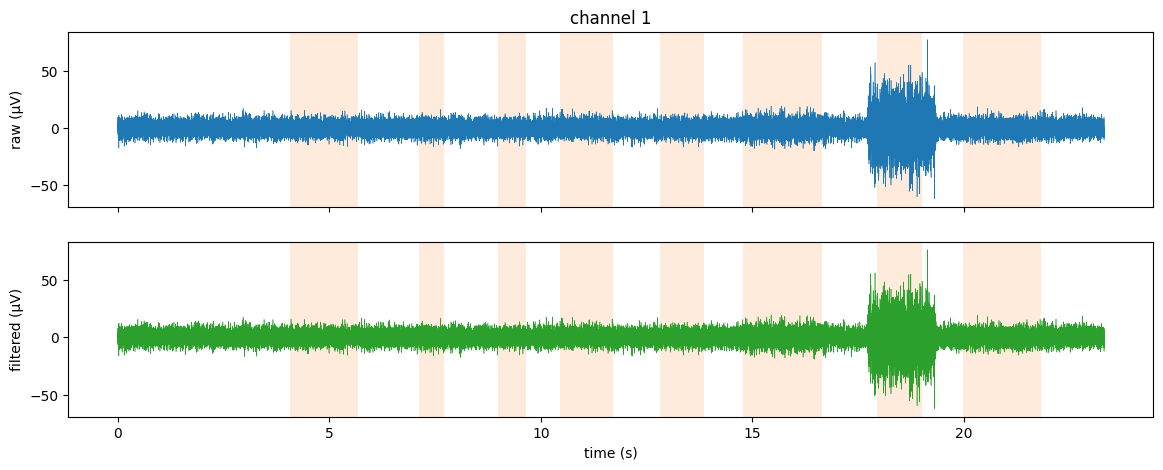

In [5]:
CH = 0
fig, axs = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axs[0].plot(t, trial.emg_uv[:, CH], lw=0.4)
axs[0].set_ylabel("raw (µV)")
axs[1].plot(t, filt.emg_uv[:, CH], lw=0.4, color="tab:green")
axs[1].set_ylabel("filtered (µV)")
for ax in axs:
    shade_prompts(ax, trial)
axs[1].set_xlabel("time (s)")
axs[0].set_title(f"channel {CH + 1}")
plt.show()

## RMS envelope heatmap (100 ms window)

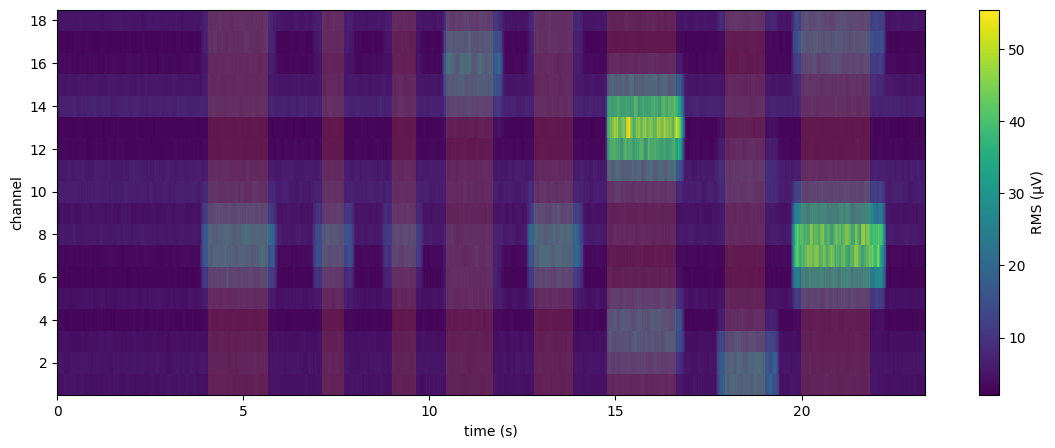

In [6]:
win = int(0.1 * FS)
env = np.sqrt(signal.convolve2d(filt.emg_uv**2, np.ones((win, 1)) / win, mode="same"))
step = win // 4
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(
    env[::step].T,
    aspect="auto",
    origin="lower",
    cmap="viridis",
    extent=[t[0], t[-1], 0.5, n_ch + 0.5],
    interpolation="nearest",
)
shade_prompts(ax, trial)
ax.set_xlabel("time (s)")
ax.set_ylabel("channel")
fig.colorbar(im, ax=ax, label="RMS (µV)")
plt.show()

## Power spectrum (Welch), raw vs filtered

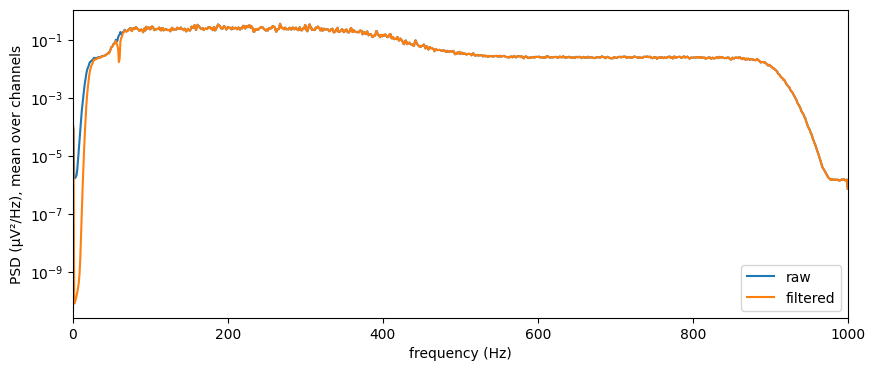

In [7]:
f, p_raw = signal.welch(trial.emg_uv, fs=FS, nperseg=2048, axis=0)
_, p_filt = signal.welch(filt.emg_uv, fs=FS, nperseg=2048, axis=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f, p_raw.mean(axis=1), label="raw")
ax.semilogy(f, p_filt.mean(axis=1), label="filtered")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("PSD (µV²/Hz), mean over channels")
ax.legend()
ax.set_xlim(0, FS / 2)
plt.show()

## IMU

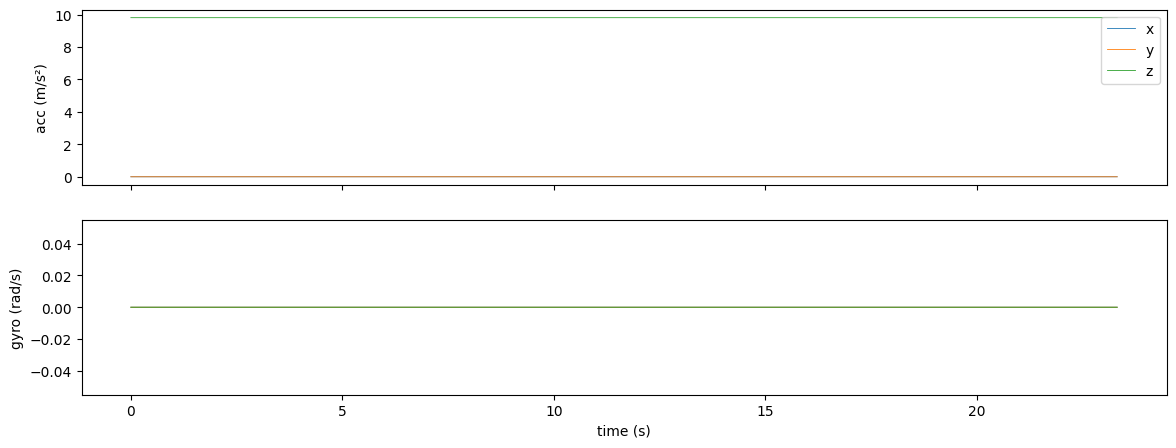

In [8]:
ti = (trial.imu_t_ns - trial.emg_t_ns[0]) / 1e9
fig, axs = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for k, name in enumerate("xyz"):
    axs[0].plot(ti, trial.acc[:, k], lw=0.6, label=name)
    axs[1].plot(ti, trial.gyro[:, k], lw=0.6, label=name)
axs[0].set_ylabel("acc (m/s²)")
axs[1].set_ylabel("gyro (rad/s)")
axs[0].legend(loc="upper right")
axs[1].set_xlabel("time (s)")
plt.show()